In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Titanic EDA Project Started Successfully!")

Titanic EDA Project Started Successfully!


# TITANIC – EXPLORATORY DATA ANALYSIS (EDA)

## Project Overview

Exploratory Data Analysis (EDA) is the process of
analyzing a dataset to discover patterns, trends and
meaningful insights.

In this project, we will analyze the Titanic passenger
dataset using Python and its data science libraries.

## Objectives

1. Understand the Titanic dataset.
2. Identify and handle missing values.
3. Perform data cleaning.
4. Analyze survival rates.
5. Create graphical visualizations.
6. Draw meaningful conclusions.

## Research Questions

1. Did women have a higher survival rate than men?
2. Did passenger class affect survival?
3. Was age related to survival?

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set graph style
sns.set_theme(style="whitegrid")

# Display all columns
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# Load Titanic dataset

df = sns.load_dataset("titanic")

print("Titanic dataset loaded successfully!")


Titanic dataset loaded successfully!


In [4]:
# display first five rows
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
df.shape

(891, 15)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [7]:
df.describe()


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


## Understanding the Dataset Columns

The Titanic dataset contains information about passengers.

Each column represents a different passenger attribute,
such as age, gender, ticket class and survival status.

In [9]:
# Display all column names

print("Dataset Columns:")

for column in df.columns:
    print(column)

Dataset Columns:
survived
pclass
sex
age
sibsp
parch
fare
embarked
class
who
adult_male
deck
embark_town
alive
alone


In [10]:
# Display the data types of all columns

df.dtypes

survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

In [11]:
# Check dataset dimensions

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 891
Columns: 15


## Understanding the Dataset

The Titanic dataset contains 15 columns that provide information
about passengers, including their age, gender, ticket class,
fare, family members, and survival status.

In [12]:
import pandas as pd
import seaborn as sns

# Load Titanic dataset
df = sns.load_dataset("titanic")

# Check dataset
print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 891
Columns: 15


In [13]:
print(df.columns.tolist())
print(df.isnull().sum())
print((df.isnull().mean() * 100).round(2))

['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64
survived        0.00
pclass          0.00
sex             0.00
age            19.87
sibsp           0.00
parch           0.00
fare            0.00
embarked        0.22
class           0.00
who             0.00
adult_male      0.00
deck           77.22
embark_town     0.22
alive           0.00
alone           0.00
dtype: float64


In [14]:
# Display all column names
print("COLUMN NAMES:")
print(df.columns.tolist())

# Count missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# Calculate missing values percentage
print("\nMISSING VALUES PERCENTAGE:")
print((df.isnull().mean() * 100).round(2))

COLUMN NAMES:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

MISSING VALUES:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

MISSING VALUES PERCENTAGE:
survived        0.00
pclass          0.00
sex             0.00
age            19.87
sibsp           0.00
parch           0.00
fare            0.00
embarked        0.22
class           0.00
who             0.00
adult_male      0.00
deck           77.22
embark_town     0.22
alive           0.00
alone           0.00
dtype: float64


In [15]:
# Fill missing ages using median age by class and sex
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

# Fill missing embarked values with mode
df["embarked"] = df["embarked"].fillna(
    df["embarked"].mode()[0]
)

# Fill missing embark_town values with mode
df["embark_town"] = df["embark_town"].fillna(
    df["embark_town"].mode()[0]
)

# Drop deck column because it has too many missing values
df = df.drop(columns=["deck"])

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


In [16]:
print("Total missing values:", df.isnull().sum().sum())
print("Updated dataset shape:", df.shape)

Total missing values: 0
Updated dataset shape: (891, 14)


In [17]:
# Count duplicate rows
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 118


In [18]:
# Display data types of all columns
print("DATA TYPES:")
print(df.dtypes)

DATA TYPES:
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
embark_town      object
alive            object
alone              bool
dtype: object


In [19]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          891 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     891 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  embark_town  891 non-null    object  
 12  alive        891 non-null    object  
 13  alone        891 non-null    bool    
dtypes: bool(2), category(1), float64(2), int64(4), object(5)
memory usage: 79.4+ KB


## 1. Survival Analysis Based on Gender

In this section, we will compare the survival rates of male and female passengers to understand whether gender influenced survival chances.

In [20]:
# Calculate survival rate by gender
gender_survival = df.groupby("sex")["survived"].mean() * 100

# Display results
print("Survival Rate by Gender:")
print(gender_survival.round(2))

Survival Rate by Gender:
sex
female    74.20
male      18.89
Name: survived, dtype: float64


In [21]:
gender_analysis = df.groupby("sex")["survived"].agg(
    Total_Passengers="count",
    Total_Survivors="sum",
    Survival_Rate="mean"
)

gender_analysis["Survival_Rate"] = (
    gender_analysis["Survival_Rate"] * 100
).round(2)

print(gender_analysis)

        Total_Passengers  Total_Survivors  Survival_Rate
sex                                                     
female               314              233          74.20
male                 577              109          18.89


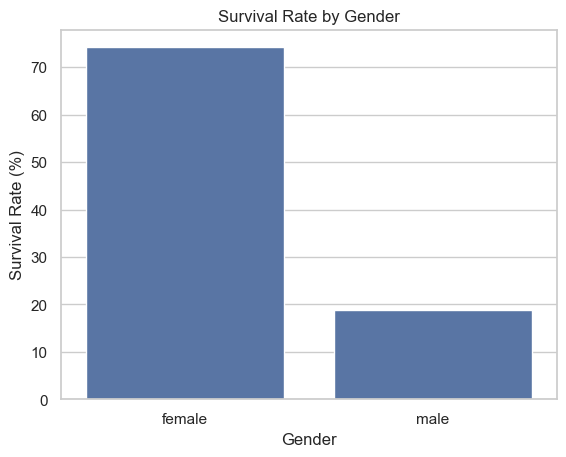

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.barplot(
    x=gender_survival.index,
    y=gender_survival.values
)

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.show()

## 2. Survival Analysis Based on Passenger Class

In this section, we will compare the survival rates of passengers travelling in First, Second, and Third class.

In [23]:
# Calculate survival rate by passenger class
class_survival = df.groupby("pclass")["survived"].mean() * 100

print("Survival Rate by Passenger Class:")
print(class_survival.round(2))

Survival Rate by Passenger Class:
pclass
1    62.96
2    47.28
3    24.24
Name: survived, dtype: float64


In [24]:
class_analysis = df.groupby("pclass")["survived"].agg(
    Total_Passengers="count",
    Total_Survivors="sum",
    Survival_Rate="mean"
)

class_analysis["Survival_Rate"] = (
    class_analysis["Survival_Rate"] * 100
).round(2)

print(class_analysis)

        Total_Passengers  Total_Survivors  Survival_Rate
pclass                                                  
1                    216              136          62.96
2                    184               87          47.28
3                    491              119          24.24


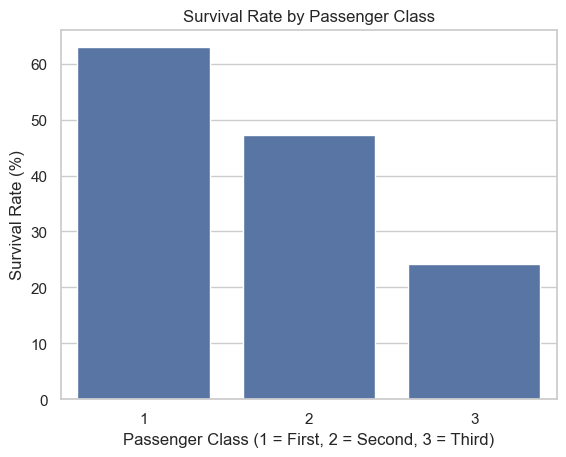

In [25]:
sns.barplot(
    x=class_survival.index,
    y=class_survival.values
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Survival Rate (%)")
plt.show()

## 3. Survival Analysis Based on Age Group

In this section, we will divide passengers into different age groups and compare their survival rates.

In [26]:
# Divide passengers into age groups
df["age_band"] = pd.cut(
    df["age"],
    bins=[0, 12, 18, 40, 60, 100],
    labels=["Child", "Teen", "Adult", "Middle-aged", "Senior"],
    include_lowest=True
)

print("Age Groups Created Successfully!")
print(df[["age", "age_band"]].head(10))

Age Groups Created Successfully!
    age     age_band
0  22.0        Adult
1  38.0        Adult
2  26.0        Adult
3  35.0        Adult
4  35.0        Adult
5  25.0        Adult
6  54.0  Middle-aged
7   2.0        Child
8  27.0        Adult
9  14.0         Teen


In [27]:
# Calculate survival rate by age group
age_survival = df.groupby(
    "age_band", observed=True
)["survived"].mean() * 100

print("Survival Rate by Age Group:")
print(age_survival.round(2))

Survival Rate by Age Group:
age_band
Child          57.97
Teen           42.86
Adult          36.05
Middle-aged    39.06
Senior         22.73
Name: survived, dtype: float64


In [28]:
age_analysis = df.groupby(
    "age_band", observed=True
)["survived"].agg(
    Total_Passengers="count",
    Total_Survivors="sum",
    Survival_Rate="mean"
)

age_analysis["Survival_Rate"] = (
    age_analysis["Survival_Rate"] * 100
).round(2)

print(age_analysis)

             Total_Passengers  Total_Survivors  Survival_Rate
age_band                                                     
Child                      69               40          57.97
Teen                       70               30          42.86
Adult                     602              217          36.05
Middle-aged               128               50          39.06
Senior                     22                5          22.73


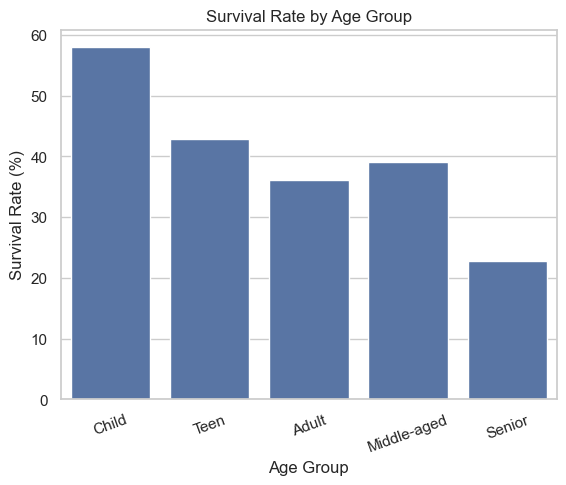

In [29]:
sns.barplot(
    x=age_survival.index,
    y=age_survival.values
)

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=20)
plt.show()

## 4. Grouping and Aggregation

Grouping and aggregation help us compare passenger survival across multiple categories using Pandas.

In [30]:
# Group data by gender and passenger class
group_analysis = df.groupby(
    ["sex", "pclass"]
)["survived"].agg(
    Total_Passengers="count",
    Total_Survivors="sum",
    Survival_Rate="mean"
)

group_analysis["Survival_Rate"] = (
    group_analysis["Survival_Rate"] * 100
).round(2)

print(group_analysis)

               Total_Passengers  Total_Survivors  Survival_Rate
sex    pclass                                                  
female 1                     94               91          96.81
       2                     76               70          92.11
       3                    144               72          50.00
male   1                    122               45          36.89
       2                    108               17          15.74
       3                    347               47          13.54


In [31]:
# Sort results from highest to lowest survival rate
sorted_analysis = group_analysis.sort_values(
    by="Survival_Rate",
    ascending=False
)

print("Survival Analysis (Highest to Lowest):")
print(sorted_analysis)

Survival Analysis (Highest to Lowest):
               Total_Passengers  Total_Survivors  Survival_Rate
sex    pclass                                                  
female 1                     94               91          96.81
       2                     76               70          92.11
       3                    144               72          50.00
male   1                    122               45          36.89
       2                    108               17          15.74
       3                    347               47          13.54


In [32]:
fare_analysis = df.groupby("pclass")["fare"].agg(
    Average_Fare="mean",
    Minimum_Fare="min",
    Maximum_Fare="max"
)

print("Ticket Fare Analysis:")
print(fare_analysis.round(2))

Ticket Fare Analysis:
        Average_Fare  Minimum_Fare  Maximum_Fare
pclass                                          
1              84.15           0.0        512.33
2              20.66           0.0         73.50
3              13.68           0.0         69.55


## 5. Correlation Analysis

Correlation measures the strength and direction of relationships between numerical variables.

In [33]:
# Select numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Calculate correlation
correlation = numeric_df.corr()

print(correlation.round(2))

          survived  pclass   age  sibsp  parch  fare
survived      1.00   -0.34 -0.06  -0.04   0.08  0.26
pclass       -0.34    1.00 -0.41   0.08   0.02 -0.55
age          -0.06   -0.41  1.00  -0.25  -0.18  0.12
sibsp        -0.04    0.08 -0.25   1.00   0.41  0.16
parch         0.08    0.02 -0.18   0.41   1.00  0.22
fare          0.26   -0.55  0.12   0.16   0.22  1.00


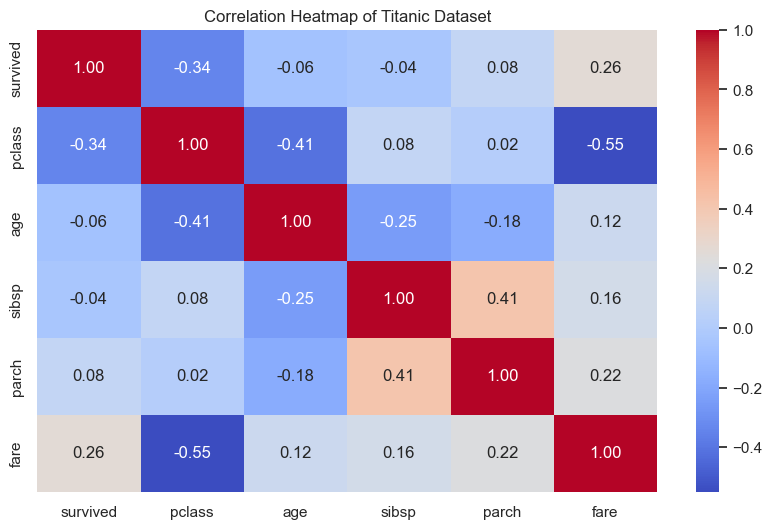

In [34]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Titanic Dataset")
plt.show()

## 6. Key Findings and Observations

This section summarizes the important findings obtained from the exploratory data analysis of the Titanic dataset.

In [35]:
# Overall survival statistics
total_passengers = len(df)
total_survivors = df["survived"].sum()
total_deaths = total_passengers - total_survivors

survival_percentage = (total_survivors / total_passengers) * 100
death_percentage = (total_deaths / total_passengers) * 100

print("TITANIC DATASET SUMMARY")
print("-----------------------")
print("Total Passengers:", total_passengers)
print("Total Survivors:", total_survivors)
print("Total Deaths:", total_deaths)
print("Survival Rate:", round(survival_percentage, 2), "%")
print("Death Rate:", round(death_percentage, 2), "%")

print("\nHIGHEST SURVIVAL RATE BY:")
print("Gender:", gender_survival.idxmax())
print("Passenger Class:", class_survival.idxmax())
print("Age Group:", age_survival.idxmax())

TITANIC DATASET SUMMARY
-----------------------
Total Passengers: 891
Total Survivors: 342
Total Deaths: 549
Survival Rate: 38.38 %
Death Rate: 61.62 %

HIGHEST SURVIVAL RATE BY:
Gender: female
Passenger Class: 1
Age Group: Child


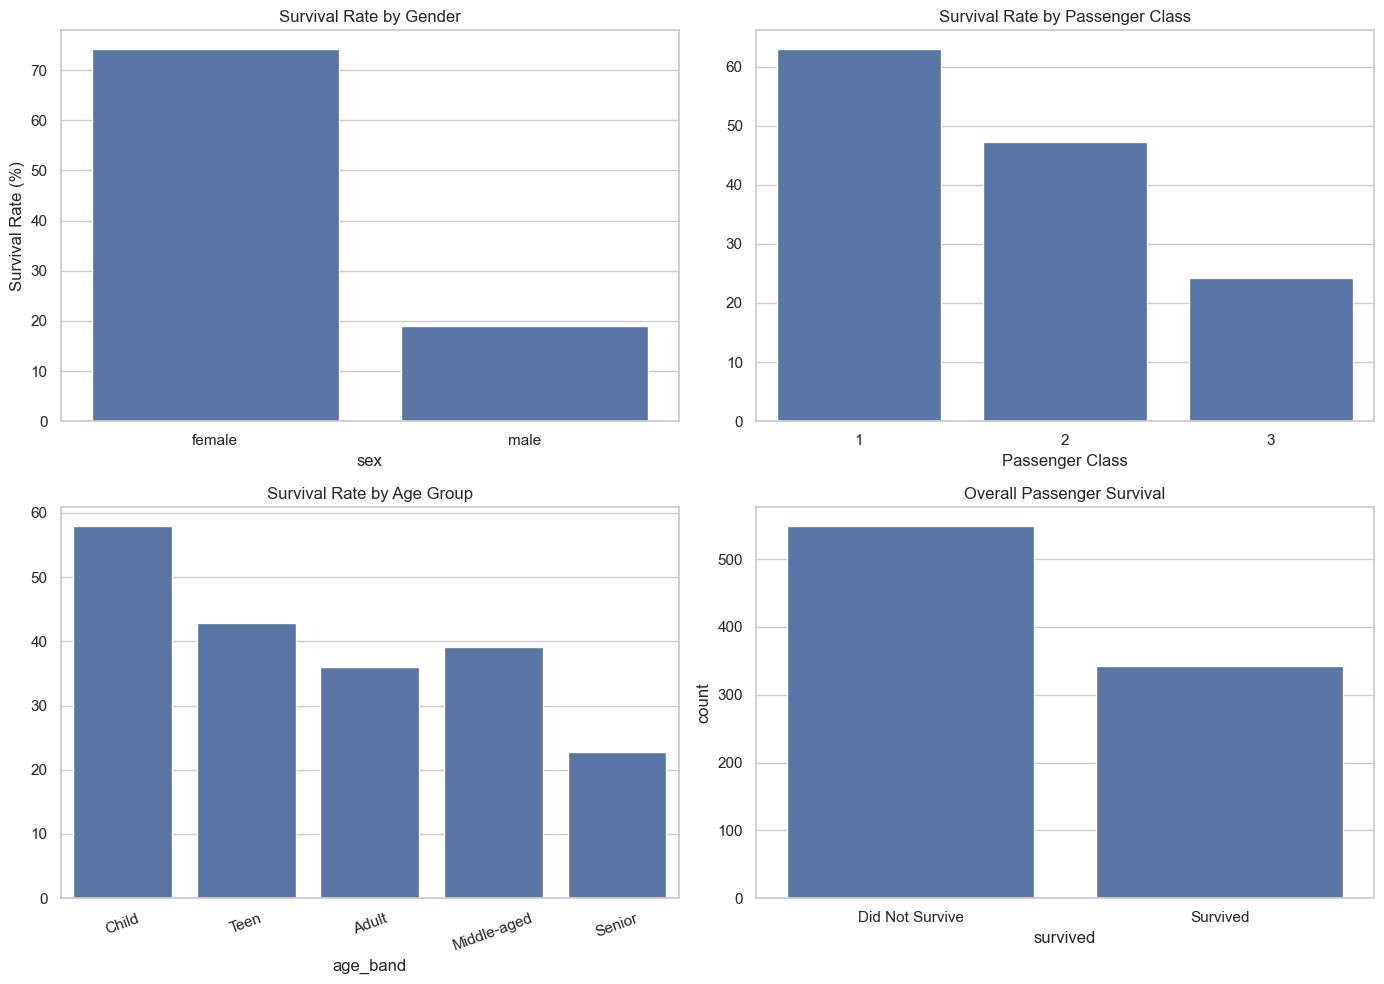

In [36]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gender analysis
sns.barplot(
    x=gender_survival.index,
    y=gender_survival.values,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Survival Rate by Gender")
axes[0, 0].set_ylabel("Survival Rate (%)")

# Passenger class analysis
sns.barplot(
    x=class_survival.index,
    y=class_survival.values,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Survival Rate by Passenger Class")
axes[0, 1].set_xlabel("Passenger Class")

# Age analysis
sns.barplot(
    x=age_survival.index,
    y=age_survival.values,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Survival Rate by Age Group")
axes[1, 0].tick_params(axis="x", rotation=20)

# Overall survival
sns.countplot(
    x="survived",
    data=df,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Overall Passenger Survival")
axes[1, 1].set_xticks([0, 1], ["Did Not Survive", "Survived"])

plt.tight_layout()
plt.show()

## 7. Conclusion

Exploratory Data Analysis was performed on the Titanic dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn.

The dataset was inspected, cleaned, and analyzed to understand passenger survival patterns. Missing values were handled using suitable statistical methods, and duplicate records and data types were examined.

The analysis compared survival rates based on gender, passenger class, and age groups. Grouping, aggregation, sorting, and correlation analysis were also performed.

The project demonstrates how data analysis techniques can help identify patterns, understand datasets, and extract meaningful insights from raw data.

In [37]:
print("FINAL PROJECT CHECK")
print("--------------------")

print("Dataset Shape:", df.shape)
print("Total Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nColumns in Dataset:")
print(df.columns.tolist())

print("\nProject Libraries:")
print("Pandas, NumPy, Matplotlib, Seaborn")

FINAL PROJECT CHECK
--------------------
Dataset Shape: (891, 15)
Total Missing Values: 0
Duplicate Rows: 118

Columns in Dataset:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone', 'age_band']

Project Libraries:
Pandas, NumPy, Matplotlib, Seaborn
